# Empirical Analysis of Sorting Algorithms
Analysis of Algorithms | Assignment 2

This notebook implements Bubble Sort, Selection Sort, Insertion Sort and Merge Sort, measures their execution time for N = 5, 10, 50 and 100, plots the results and compares them with the theoretical time complexity.

## 1. Imports
Libraries used for random test data, timing, statistics, tables and plotting.

In [1]:
import random
import time
import statistics
import math
import pandas as pd
import matplotlib.pyplot as plt

## 2. Sorting Algorithms
Each function sorts the list in place.

| Algorithm | Best case | Worst case |
|---|---|---|
| Bubble Sort | O(n²) | O(n²) |
| Selection Sort | O(n²) | O(n²) |
| Insertion Sort | O(n) | O(n²) |
| Merge Sort | O(n log n) | O(n log n) |

Bubble Sort here has no early-exit flag, so it is O(n²) even on sorted input. After the definitions, each algorithm is checked against Python's built-in `sorted()` on random lists.

In [2]:
def bubble_sort(arr):
    n = len(arr)
    for i in range(n - 1):
        for j in range(n - 1 - i):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]


def selection_sort(arr):
    n = len(arr)
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            if arr[j] < arr[min_idx]:
                min_idx = j
        arr[i], arr[min_idx] = arr[min_idx], arr[i]


def insertion_sort(arr):
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        while j >= 0 and arr[j] > key:
            arr[j + 1] = arr[j]
            j -= 1
        arr[j + 1] = key


def merge_sort(arr):
    if len(arr) <= 1:
        return
    mid = len(arr) // 2
    left = arr[:mid]
    right = arr[mid:]
    merge_sort(left)
    merge_sort(right)
    i = j = k = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            arr[k] = left[i]
            i += 1
        else:
            arr[k] = right[j]
            j += 1
        k += 1
    while i < len(left):
        arr[k] = left[i]
        i += 1
        k += 1
    while j < len(right):
        arr[k] = right[j]
        j += 1
        k += 1


algorithms = {
    "Bubble Sort": bubble_sort,
    "Selection Sort": selection_sort,
    "Insertion Sort": insertion_sort,
    "Merge Sort": merge_sort,
}

for name, func in algorithms.items():
    for size in [0, 1, 2, 5, 10, 50, 100]:
        for _ in range(20):
            original = [random.randint(0, 1000) for _ in range(size)]
            test = original.copy()
            func(test)
            assert test == sorted(original), f"{name} failed for size {size}"
    print(f"{name}: OK")

Bubble Sort: OK
Selection Sort: OK
Insertion Sort: OK
Merge Sort: OK


## 3. Inputs and Timing Method
- **Inputs:** the given arrays {1..N} are already sorted (best case for Insertion Sort). Reverse-sorted arrays {N..1} are also generated as the worst case.
- **Timer:** `time.perf_counter_ns()`, converted to microseconds (µs).
- **Runs:** 100 per size (minimum required is 5), after 10 warm-up runs. Garbage collection is turned off while timing. The slowest 20% of runs are dropped because they contain random system spikes, and the average of the remaining runs is reported.
- **Fresh copy:** the array is copied before every run (outside the timed part), since sorting happens in place.

In [3]:
import gc

sizes = [5, 10, 50, 100]
sorted_inputs = {n: list(range(1, n + 1)) for n in sizes}
worst_inputs = {n: list(range(n, 0, -1)) for n in sizes}

RUNS = 100      # timed runs per size
WARMUP = 10     # warm-up runs (not counted)
TRIM = 0.2      # drop the slowest 20% of runs (random spikes)


def measure(func, data, runs=RUNS):
    for _ in range(WARMUP):
        func(data.copy())
    gc.disable()                      # stop garbage collector from adding spikes
    times = []
    for _ in range(runs):
        arr = data.copy()             # fresh copy, outside the timed part
        start = time.perf_counter_ns()
        func(arr)
        end = time.perf_counter_ns()
        times.append((end - start) / 1000)   # microseconds
    gc.enable()
    times.sort()
    kept = times[:int(runs * (1 - TRIM))]    # keep the fastest 80%
    return statistics.mean(kept), statistics.stdev(kept)


def run_experiment(inputs):
    means, stds = {}, {}
    for name, func in algorithms.items():
        m_list, s_list = [], []
        for n in sizes:
            m, s = measure(func, inputs[n])
            m_list.append(m)
            s_list.append(s)
        means[name] = m_list
        stds[name] = s_list
    mean_df = pd.DataFrame(means, index=sizes)
    std_df = pd.DataFrame(stds, index=sizes)
    mean_df.index.name = "N"
    std_df.index.name = "N"
    return mean_df, std_df


worst_mean, worst_std = run_experiment(worst_inputs)
sorted_mean, sorted_std = run_experiment(sorted_inputs)

print("Average execution time (µs) - worst case (reverse sorted)")
display(worst_mean.round(2))
print("Average execution time (µs) - given arrays (sorted)")
display(sorted_mean.round(2))
print("Standard deviation (µs) - worst case")
display(worst_std.round(2))
print("Standard deviation (µs) - sorted input")
display(sorted_std.round(2))

Average execution time (µs) - worst case (reverse sorted)


,Bubble Sort,Selection Sort,Insertion Sort,Merge Sort
N,,,,
5,1.60,1.16,1.36,3.08
10,5.45,3.38,4.37,7.39
50,118.79,54.89,99.07,48.14
100,469.17,201.09,389.31,110.51


Average execution time (µs) - given arrays (sorted)


,Bubble Sort,Selection Sort,Insertion Sort,Merge Sort
N,,,,
5,1.17,1.17,0.63,2.71
10,3.22,3.05,1.04,6.56
50,59.46,51.25,4.58,45.90
100,234.78,191.64,8.88,107.21


Standard deviation (µs) - worst case


,Bubble Sort,Selection Sort,Insertion Sort,Merge Sort
N,,,,
5,0.04,0.04,0.04,0.02
10,0.12,0.02,0.13,0.21
50,5.34,2.68,4.63,1.34
100,20.74,8.23,14.19,3.54


Standard deviation (µs) - sorted input


,Bubble Sort,Selection Sort,Insertion Sort,Merge Sort
N,,,,
5,0.05,0.04,0.06,0.03
10,0.10,0.02,0.01,0.02
50,1.79,1.60,0.02,2.16
100,8.08,5.40,0.18,2.66


## 4. Graphs
Average execution time (µs) against input size N for the worst case and for the given sorted arrays. The log-log plot makes the growth rates easier to compare: steeper lines mean faster growth.

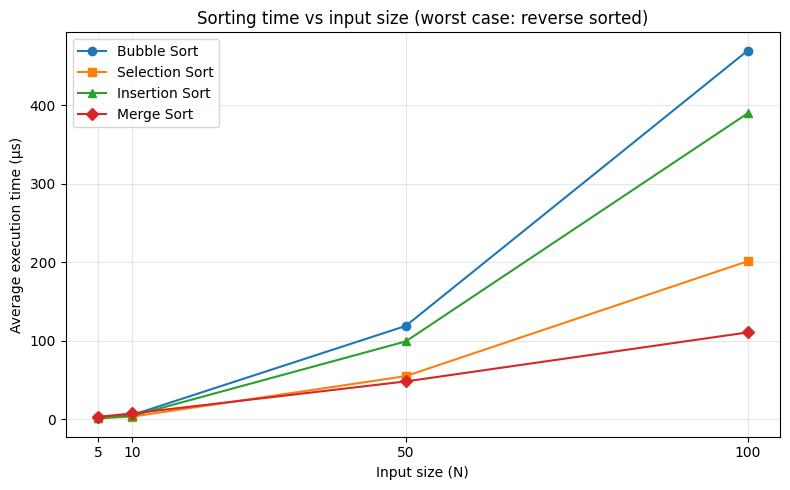

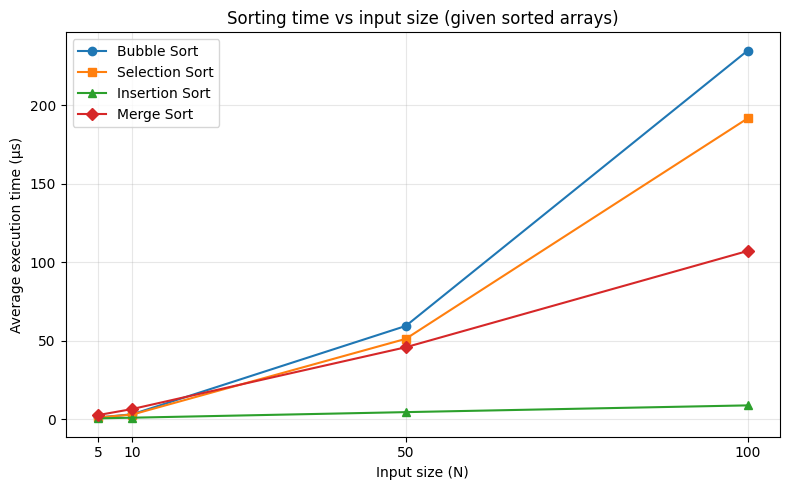

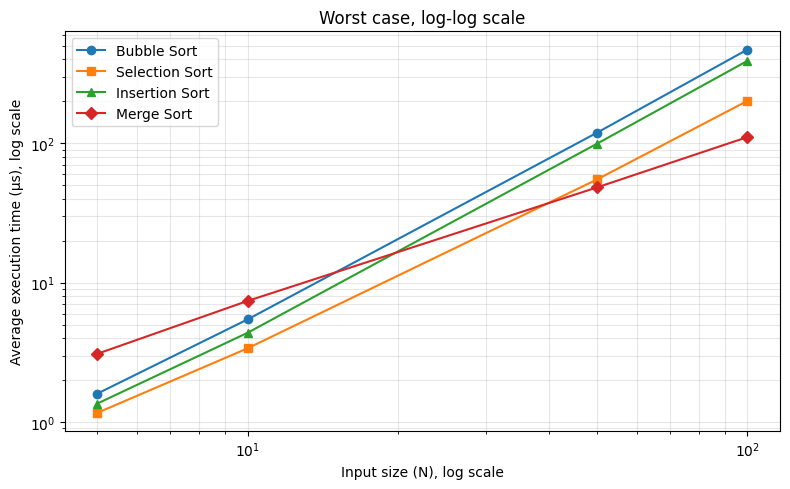

In [4]:
markers = {"Bubble Sort": "o", "Selection Sort": "s", "Insertion Sort": "^", "Merge Sort": "D"}


def plot_results(df, title, filename):
    plt.figure(figsize=(8, 5))
    for name in df.columns:
        plt.plot(df.index, df[name], marker=markers[name], label=name)
    plt.xlabel("Input size (N)")
    plt.ylabel("Average execution time (µs)")
    plt.title(title)
    plt.xticks(sizes)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()


plot_results(worst_mean, "Sorting time vs input size (worst case: reverse sorted)", "graph_worst_case.png")
plot_results(sorted_mean, "Sorting time vs input size (given sorted arrays)", "graph_sorted_input.png")

plt.figure(figsize=(8, 5))
for name in worst_mean.columns:
    plt.plot(worst_mean.index, worst_mean[name], marker=markers[name], label=name)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Input size (N), log scale")
plt.ylabel("Average execution time (µs), log scale")
plt.title("Worst case, log-log scale")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("graph_worst_case_loglog.png", dpi=200)
plt.show()

## 5. Empirical vs Theoretical Growth
Going from N = 50 to N = 100, an O(n²) algorithm should take about 4x longer, O(n log n) about 2.35x, and O(n) about 2x. The table compares these values with the measured ratios. The results are also saved as CSV files.

In [5]:
theory_n2 = (100 ** 2) / (50 ** 2)
theory_nlogn = (100 * math.log2(100)) / (50 * math.log2(50))

ratios = pd.DataFrame({
    "Worst case: T(100)/T(50)": worst_mean.loc[100] / worst_mean.loc[50],
    "Sorted input: T(100)/T(50)": sorted_mean.loc[100] / sorted_mean.loc[50],
})
ratios.index.name = "Algorithm"

print(f"Theory: O(n^2) = {theory_n2:.2f}x | O(n log n) = {theory_nlogn:.2f}x | O(n) = 2.00x")
display(ratios.round(2))

worst_mean.round(3).to_csv("results_worst_case.csv")
sorted_mean.round(3).to_csv("results_sorted_input.csv")

Theory: O(n^2) = 4.00x | O(n log n) = 2.35x | O(n) = 2.00x


,Worst case: T(100)/T(50),Sorted input: T(100)/T(50)
Algorithm,,
Bubble Sort,3.95,3.95
Selection Sort,3.66,3.74
Insertion Sort,3.93,1.94
Merge Sort,2.30,2.34


## Getting the important files

In [6]:
import zipfile
from google.colab import files

names = [
    "results_worst_case.csv",
    "results_sorted_input.csv",
    "graph_worst_case.png",
    "graph_sorted_input.png",
    "graph_worst_case_loglog.png",
]

with zipfile.ZipFile("results_bundle.zip", "w") as z:
    for n in names:
        z.write(n)

files.download("results_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>